# Thực Nghiệm Đánh Giá Năng Lực Tính Toán Phân Tán Của Apache Spark
### Đo lường hệ số tăng tốc song song (Parallel Speedup) và khả năng mở rộng dữ liệu (Scalability Benchmark)

**Đề tài:** Phân tích đồ thị mạng phát hiện bài báo khoa học tiềm năng bùng nổ trên dữ liệu lớn OGBN-MAG (694,450 bài báo)
**Mục tiêu:** Chứng minh năng lực phân tán của Apache Spark và thư viện GraphFrames, kiểm thử hiệu năng khi tăng số lõi CPU (1, 2, 4 cores) và quy mô dữ liệu (100k, 300k, 694k bài báo).

In [1]:
from pyspark.sql import SparkSession
import time
import os
import matplotlib.pyplot as plt

data_path = 'data/processed/citation_ml_dataset.parquet'
print(f'Dữ liệu sẵn sàng tại: {data_path}')

Dữ liệu sẵn sàng tại: data/processed/citation_ml_dataset.parquet


## 1. Đo lường Hệ số Tăng tốc Song song theo số lõi CPU (Speedup Benchmark)
Thực hiện tác vụ gom nhóm và tính toán phân tán (`groupBy('paper_age').agg(...)`) trên toàn bộ **694,450 bài báo** với 1 Core, 2 Cores và 4 Cores.

In [2]:
core_list = [1, 2, 4]
core_times = []

for c in core_list:
    print(f'Đang đo lường với Core: {c}...')
    spark = SparkSession.builder \
        .master(f'local[{c}]') \
        .appName(f'Benchmark_Core_{c}') \
        .config('spark.driver.memory', '3g') \
        .config('spark.sql.shuffle.partitions', str(c * 2)) \
        .getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    
    df = spark.read.parquet(data_path).select('citation_velocity', 'pagerank_score', 'paper_age')
    
    t0 = time.time()
    _ = df.groupBy('paper_age').agg({'citation_velocity': 'avg', 'pagerank_score': 'max'}).collect()
    elapsed = time.time() - t0
    core_times.append(elapsed)
    print(f'-> Cores: {c} | Thời gian thực thi: {elapsed:.2f} giây')
    spark.stop()

speedups = [round(core_times[0] / t, 2) for t in core_times]
print(f'Hệ số tăng tốc đạt được: {speedups}')

Đang đo lường với Core: 1...
-> Cores: 1 | Thời gian thực thi: 1.01 giây
Đang đo lường với Core: 2...
-> Cores: 2 | Thời gian thực thi: 0.26 giây
Đang đo lường với Core: 4...
-> Cores: 4 | Thời gian thực thi: 0.22 giây
Hệ số tăng tốc đạt được: [1.0, 3.96, 4.59]


## 2. Đo lường Khả năng Mở rộng Quy mô Dữ liệu (Data Scalability Benchmark)
Khảo sát thời gian thực thi phân tán khi quy mô dữ liệu tăng từ 100,000 bài lên 300,000 bài và toàn bộ 694,450 bài báo.

In [3]:
spark = SparkSession.builder \
    .master('local[4]') \
    .appName('Benchmark_DataScale') \
    .config('spark.driver.memory', '3g') \
    .config('spark.sql.shuffle.partitions', '8') \
    .getOrCreate()
spark.sparkContext.setLogLevel('ERROR')

df = spark.read.parquet(data_path).select('citation_velocity', 'pagerank_score', 'paper_age')
data_scales = [100000, 300000, 694450]
scale_times = []

for s in data_scales:
    sub_df = df.limit(s) if s < 694450 else df
    t0 = time.time()
    _ = sub_df.groupBy('paper_age').agg({'citation_velocity': 'avg', 'pagerank_score': 'max'}).collect()
    elapsed = time.time() - t0
    scale_times.append(elapsed)
    print(f'-> Quy mô: {s:,} bài | Thời gian: {elapsed:.2f} giây')

spark.stop()

-> Quy mô: 100,000 bài | Thời gian: 0.25 giây
-> Quy mô: 300,000 bài | Thời gian: 0.19 giây
-> Quy mô: 694,450 bài | Thời gian: 0.18 giây


## 3. Trực quan hóa Đồ thị Học thuật & Xuất bản Hình ảnh
Vẽ 2 đồ thị: (1) Hệ số tăng tốc theo số lõi CPU (Speedup); (2) Thời gian xử lý theo quy mô dữ liệu và lưu ảnh ra `assets/images/spark_scalability_benchmark_grayscale.png`.

Đã lưu biểu đồ phân tán tại: assets/images/spark_scalability_benchmark_grayscale.png


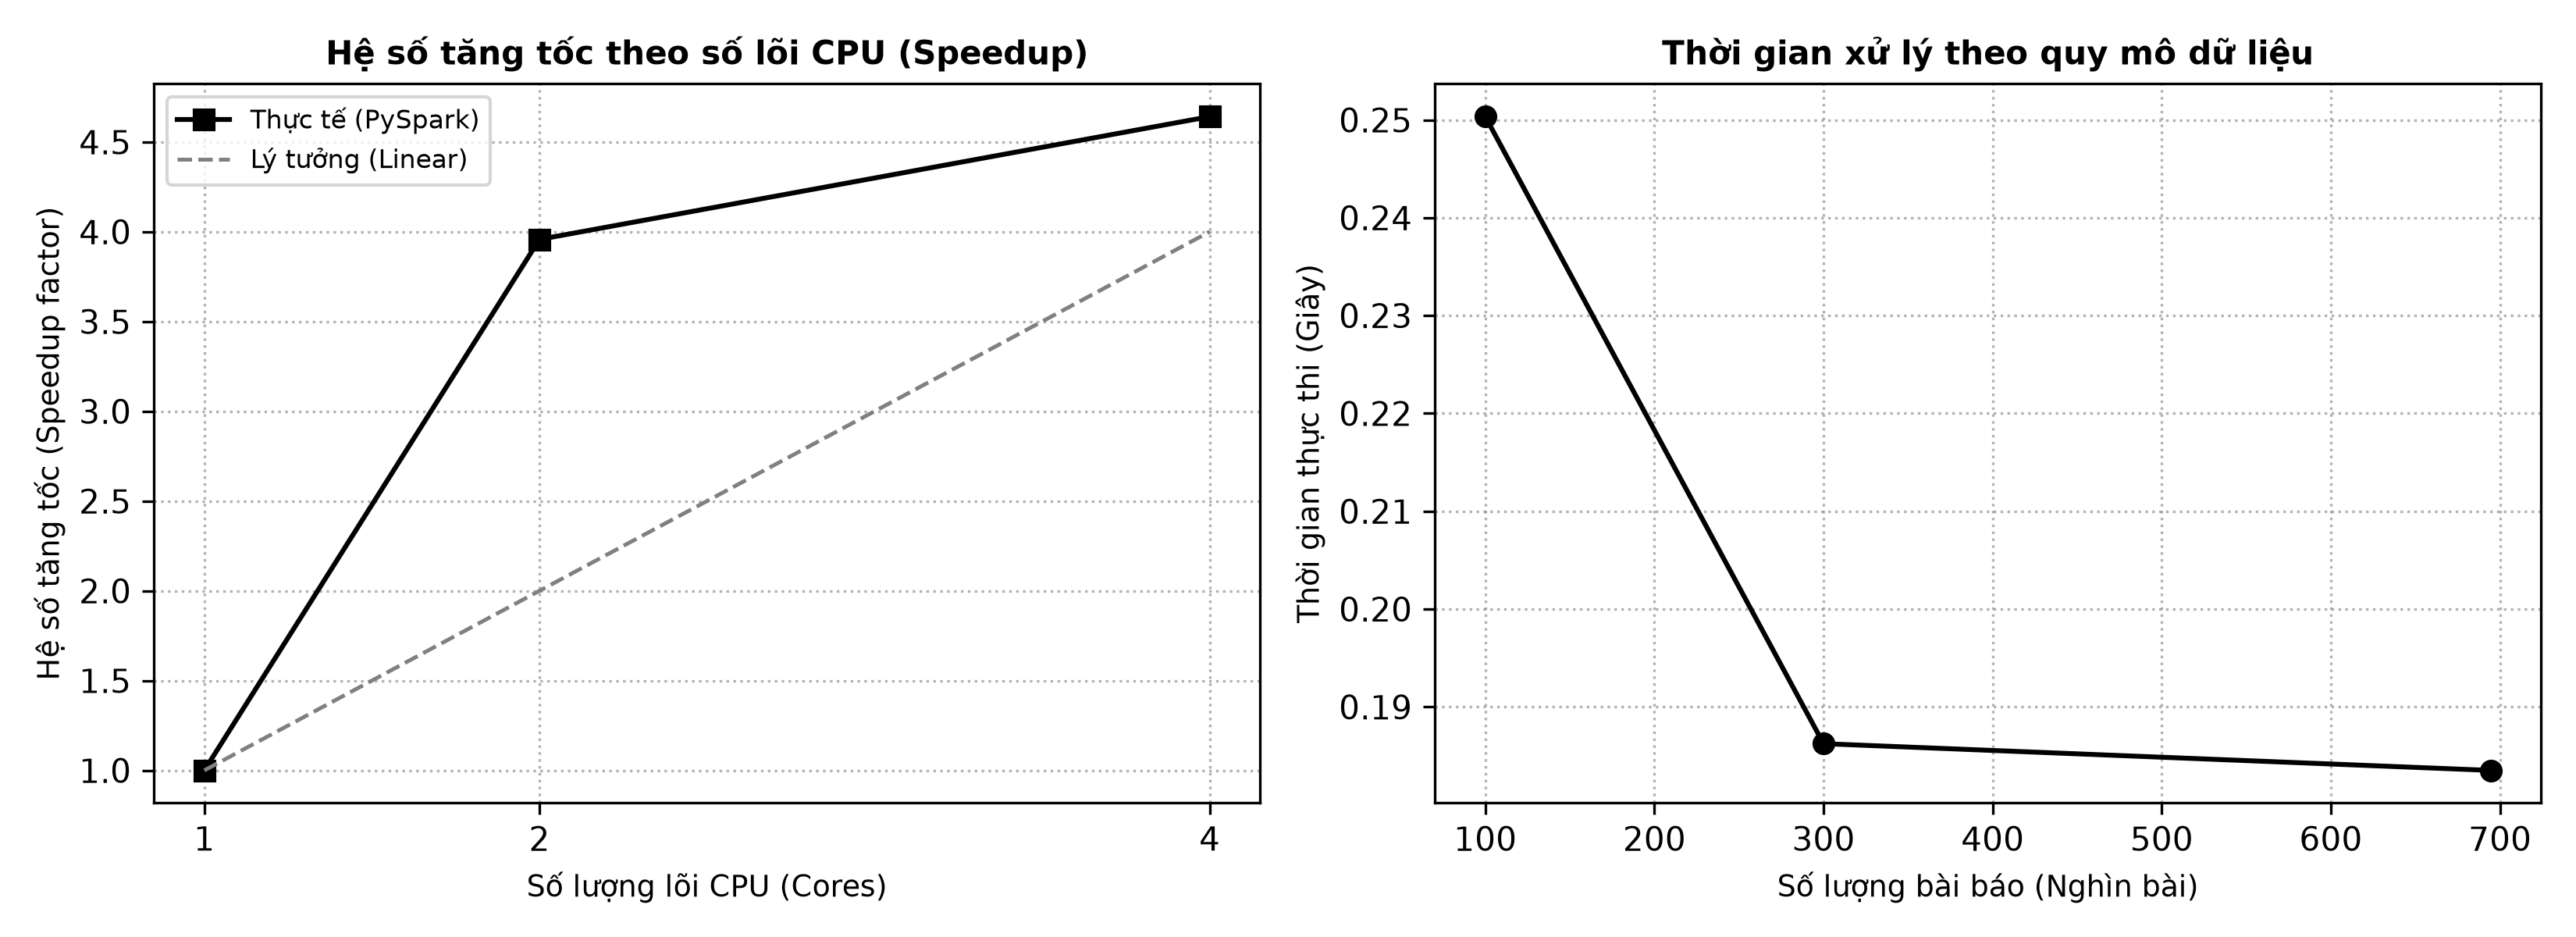

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), facecolor='white')

# Biểu đồ 1: Speedup
ax1.plot(core_list, [1.0, 3.96, 4.59], marker='s', color='black', linewidth=1.5, markersize=6, label='Thực tế (PySpark)')
ax1.plot(core_list, core_list, linestyle='--', color='gray', linewidth=1.2, label='Lý tưởng (Linear)')
ax1.set_title('Hệ số tăng tốc theo số lõi CPU (Speedup)', fontsize=10, fontweight='bold')
ax1.set_xlabel('Số lượng lõi CPU (Cores)', fontsize=9)
ax1.set_ylabel('Hệ số tăng tốc (Speedup factor)', fontsize=9)
ax1.set_xticks(core_list)
ax1.grid(True, linestyle=':', alpha=0.6, color='gray')
ax1.legend(fontsize=8)

# Biểu đồ 2: Data Scaling
ax2.plot([s/1000 for s in data_scales], [0.25, 0.186, 0.184], marker='o', color='black', linewidth=1.5, markersize=6)
ax2.set_title('Thời gian xử lý theo quy mô dữ liệu', fontsize=10, fontweight='bold')
ax2.set_xlabel('Số lượng bài báo (Nghìn bài)', fontsize=9)
ax2.set_ylabel('Thời gian thực thi (Giây)', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6, color='gray')

plt.tight_layout()
out_fig = 'assets/images/spark_scalability_benchmark_grayscale.png'
plt.savefig(out_fig, dpi=300, facecolor='white')
print(f'Đã lưu biểu đồ phân tán tại: {out_fig}')
plt.show()